<a href="https://colab.research.google.com/github/TYAhn0324/AI_drug_development/blob/main/AI_%EA%B8%B0%EB%B0%98_%EC%8B%A0%EC%95%BD%EA%B0%9C%EB%B0%9C_Virtual_screening_of_JAK2_using_Autodock_GPU_%2B_Enamine_1000_%2B_ECFP2048_MLP_%2B_GNINA_261028.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Virtual Screening of Enamine Hit Locator Library with AutoDock-GPU & Surrogate MLP Predictor (ECFP2048 + MLP)

-------
Juyong Lee

**Workflow Overview:**
1. **Part 0 ~ Part 2**: AutoDock-GPU / AutoGrid4 설치 및 표적 단백질(JAK2, PDB: `7f7w`)과 기준 리간드(`36H`) 준비, Grid Map 생성
2. **Part 3**: **Enamine Hit Locator Library (460,160 compounds)** Dropbox 다운로드 및 초기 **1,000개 분자 샘플링 → 3D PDBQT 변환 → AutoDock-GPU 도킹 수행**
3. **Part 4**: 1,000개 분자의 도킹 점수를 학습 데이터로 활용하여 **ECFP2048 (Morgan Fingerprint, radius=2, 2048 bits) + PyTorch MLP 기반 Docking Score Predictor** 학습 및 평가
4. **Part 5**: 학습된 MLP Surrogate 모델을 이용해 **나머지 459,160개 Enamine 라이브러리 전체의 도킹 점수를 고속 예측**하고 **Top Hit 후보물질 추출 및 검증 (AutoDock-GPU / GNINA)**

credit: Base AutoDock setup adapted from:
Engelberger F, Galaz-Davison P, Bravo G, Rivera M, Ramírez-Sarmiento CA (2021) J Chem Educ 98(5): 1801-1807. doi: 10.1021/acs.jchemed.1c00022

<img src="https://www.researchgate.net/publication/361504179/figure/fig2/AS:11431281099725725@1669297819906/Protein-Ligand-Visualization-Results-based-on-Docking-Results-between-EGER-PDB-1XKK.jpg" width=400>


#Part 0 – Downloading and Installing the required software

Before we start, you must first **remember to start the hosted runtime in Google Colab**.

Then, we must install several pieces of software to perform this tutorial. Namely:
- **biopython** for manipulation of the PDB files
- **py3Dmol** for visualization of the protein structure and setting up the search grid.
- **miniconda**, a free minimal installer of **conda** for software package and environment management.
- **OpenBabel** for parameterization of our ligand(s).
- **MGLtools** for parameterization of our target protein using Gasteiger charges.
- **pdb2pqr** for parameterization of our protein using the AMBER ff99 forcefield.
- **Autodock Vina** for the docking process

After several tests, the following installation instructions are the best way of setting up **Google Colab** for this laboratory session.

1. We will first install biopython, py3Dmol, and pdb2pqr as follows:

In [ ]:
#Installing py3Dmol using pip
!pip install py3Dmol
#Installing biopython using pip
!pip install biopython
#Installing pdb2pqr v3.0 using pip
!pip install pdb2pqr
#We will also install kora for using RDkit
!pip install kora

!pip install openbabel-wheel

# RDKit
# !pip install rdkit
# Meeko
# !pip install meeko

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 84.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pdb2pqr]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 93.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [kora]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 143.3 MB/s  0:00:00


In [ ]:
#Importing py3Dmol for safety
import py3Dmol

In [ ]:
!obabel --version

No input file or format spec or possibly a misplaced option.
Most options must come after the input files. (-i -o -O -m can be anywhwere.)

Open Babel 3.1.0 -- Feb 17 2026 -- 06:48:53
Usage:
obabel [-i<input-type>] <infilename> [-o<output-type>] -O<outfilename> [Options]
Try  -H option for more information.


2. And then we will install conda to be able to install MGLtools and OpenBabel

In [ ]:
#Install conda using the new conda-colab library
!pip install -q condacolab

import condacolab
condacolab.install()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

⏬ Downloading https://github.com/conda-forge/miniforge/releases/download/26.3.2-3/Miniforge3-26.3.2-3-Linux-x86_64.sh...
📦 Installing...
📌 Adjusting configuration...
🩹 Patching environment...
⏲ Done in 0:00:11
🔁 Restarting kernel...


In [ ]:
import condacolab
condacolab.check()


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to
condacolab==0.1 as a workaround.

✨🍰✨ Everything looks OK!


In [ ]:
!ldconfig -p | grep boost_system

In [ ]:
!apt-get install libboost-system-dev libboost-thread-dev libboost-filesystem-dev libboost-system-dev  libboost-program-options-dev libboost-test-dev libboost-math-dev

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libboost-atomic1.83-dev libboost-atomic1.83.0 libboost-chrono1.83-dev
  libboost-chrono1.83.0t64 libboost-date-time1.83-dev libboost-date-time1.83.0
  libboost-filesystem1.83-dev libboost-filesystem1.83.0 libboost-math1.83-dev
  libboost-math1.83.0 libboost-program-options1.83-dev
  libboost-program-options1.83.0 libboost-serialization1.83-dev
  libboost-serialization1.83.0 libboost-system1.83-dev libboost-system1.83.0
  libboost-test1.83-dev libboost-test1.83.0 libboost-thread1.83-dev
  libboost-thread1.83.0
The following NEW packages will be installed:
  libboost-atomic1.83-dev libboost-atomic1.83.0 libboost-chrono1.83-dev
  libboost-chrono1.83.0t64 libboost-date-time1.83-dev libboost-date-time1.83.0
  libboost-filesystem-dev libboost-filesystem1.83-dev
  libboost-filesystem1.83.0 libboost-math-dev libboost-math1.83-dev
  libboost-mat

In [ ]:
import multiprocessing

cores = multiprocessing.cpu_count() # Count the number of cores in a computer
cores

2

In [ ]:
#Install MGLtools and OpenBabel from
#the bioconda repository
!conda install -c conda-forge -c bioconda  mgltools  zlib numpy scipy rdkit --yes

Retrieving notices: - done
Channels:
 - conda-forge
 - bioconda
Platform: linux-64
Solving environment: / - \ | done

## Package Plan ##

  environment location: /usr/local

  added / updated specs:
    - mgltools
    - numpy
    - rdkit
    - scipy
    - zlib


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    _python_abi3_support-1.0   |       hd8ed1ab_3           8 KB  conda-forge
    annotated-types-0.8.0      |     pyhd8ed1ab_0          19 KB  conda-forge
    anyio-4.15.1               |     pyh5ded981_1         171 KB  conda-forge
    brotli-1.2.0               |       hed03a55_1          20 KB  conda-forge
    brotli-bin-1.2.0           |       hb03c661_1          21 KB  conda-forge
    ca-certificates-2026.10.23 |       hbd8a1cb_0         127 KB  conda-forge
    cached-property-2.0.1      |     pyhcf101f3_0           4 KB  conda-forge
    cached_property-2.0.1      |     

In [ ]:
import openbabel

In [ ]:
import openbabel
print(openbabel.__version__)

3.1.0


In [ ]:
!obabel

No input file or format spec or possibly a misplaced option.
Most options must come after the input files. (-i -o -O -m can be anywhwere.)

Open Babel 2.4.1 -- Jan 25 2017 -- 17:44:52
Usage:
obabel [-i<input-type>] <infilename> [-o<output-type>] -O<outfilename> [Options]
Try  -H option for more information.


# Autodock-GPU and AutoDock Vina download and install


## Installing Autodock Vina
------

In [ ]:
!git clone https://github.com/ccsb-scripps/AutoDock-Vina.git

Cloning into 'AutoDock-Vina'...
remote: Enumerating objects: 3542, done.
remote: Counting objects: 100% (984/984), done.
remote: Compressing objects: 100% (236/236), done.
remote: Total 3542 (delta 842), reused 750 (delta 748), pack-reused 2558 (from 2)
Receiving objects: 100% (3542/3542), 82.98 MiB | 19.05 MiB/s, done.
Resolving deltas: 100% (2131/2131), done.


In [ ]:
%%bash
export LDFLAGS="-L/usr/local/lib"
export CXXFLAGS="-I/usr/local/include"
cd /content/AutoDock-Vina/build/linux/release
make

g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -I ../../../src/lib -o main.o -c ../../../src/main/main.cpp 
g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -o ad4cache.o -c ../../../src/lib/ad4cache.cpp 
g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -o cache.o -c ../../../src/lib/cache.cpp 
g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -o non_cache.o -c ../../../src/lib/non_cache.cpp 
g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -o conf_independent.o -c ../../../src/lib/conf_independent.cpp 
g++ -static -pthread -ansi -Wno-long-long -O3 -DNDEBUG -std=c++11 -DVERSION=\"v1.2.7-29-gbb64e5e\" -I /usr/include  -o coords.o -c ../../../src/lib/coords.

In file included from /usr/include/boost/math/quaternion.hpp:14,
                 from ../../../src/lib/quaternion.h:26,
                 from ../../../src/lib/conf.h:28,
                 from ../../../src/lib/tree.h:26,
                 from ../../../src/lib/model.h:29,
                 from ../../../src/lib/parse_pdbqt.h:27,
                 from ../../../src/lib/vina.h:40,
                 from ../../../src/main/main.cpp:30:
/usr/include/boost/math/tools/config.hpp:23:6: warning: #warning "The minimum language standard to use Boost.Math will be C++14 starting in July 2023 (Boost 1.82 release)" [-Wcpp]
   23 | #    warning "The minimum language standard to use Boost.Math will be C++14 starting in July 2023 (Boost 1.82 release)"
      |      ^~~~~~~
In file included from /usr/include/boost/math/quaternion.hpp:14,
                 from ../../../src/lib/quaternion.h:26,
                 from ../../../src/lib/conf.h:28,
                 from ../../../src/lib/tree.h:26,
                 f

### Installing Autodock-GPU using make
------------


In [ ]:
!git clone https://github.com/ccsb-scripps/AutoDock-GPU.git

Cloning into 'AutoDock-GPU'...
remote: Enumerating objects: 6907, done.
remote: Counting objects: 100% (1395/1395), done.
remote: Compressing objects: 100% (173/173), done.
remote: Total 6907 (delta 1306), reused 1222 (delta 1222), pack-reused 5512 (from 2)
Receiving objects: 100% (6907/6907), 45.70 MiB | 20.06 MiB/s, done.
Resolving deltas: 100% (4556/4556), done.


#### Compiling Autodock-GPU
--------

In [ ]:
%%bash
export GPU_INCLUDE_PATH=/usr/local/cuda/include
export GPU_LIBRARY_PATH=/usr/local/cuda/lib64

cd AutoDock-GPU
make

Building adgpu_analysis ...
g++ \
./host/src/calcenergy.cpp ./host/src/getparameters.cpp ./host/src/main.cpp ./host/src/miscellaneous.cpp ./host/src/performdocking.cpp ./host/src/processgrid.cpp ./host/src/processligand.cpp ./host/src/processresult.cpp ./host/src/setup.cpp \
-std=c++17 -I./common -I./host/inc -DVERSION=\"v1.6-20-gbe06a135181178c8631653e1e32d9ece86b5b4d8\" \
-o./bin/adgpu_analysis \
-DUSE_PIPELINE -fopenmp  -O3 -DTOOLMODE 
DEVICE is set to GPU
 
CPU_INCLUDE_PATH is undefined
CPU_LIBRARY_PATH is undefined
 
GPU_INCLUDE_PATH is set to /usr/local/cuda/include
GPU_LIBRARY_PATH is set to /usr/local/cuda/lib64
 
nvcc -DN128WI  -use_fast_math --ptxas-options="-v" -gencode arch=compute_75,code=sm_75 -gencode arch=compute_80,code=sm_80 -gencode arch=compute_86,code=sm_86 -gencode arch=compute_87,code=sm_87 -gencode arch=compute_88,code=sm_88 -gencode arch=compute_89,code=sm_89 -gencode arch=compute_90,code=sm_90 -gencode arch=compute_100,code=sm_100 -gencode arch=compute_110,cod

Using Cuda 13.0
Compiling for targets: 75 80 86 87 88 89 90 100 110 103 120 121 
ptxas info    : 0 bytes gmem, 264 bytes cmem[3]
ptxas info    : Compiling entry function '_Z27gpu_gradient_minAdam_kernelPfS_' for 'sm_75'
ptxas info    : Function properties for _Z27gpu_gradient_minAdam_kernelPfS_
    0 bytes stack frame, 0 bytes spill stores, 0 bytes spill loads
ptxas info    : Used 64 registers, used 1 barriers, 7416 bytes smem, 368 bytes cmem[0]
ptxas info    : Compile time = 168.996 ms
ptxas info    : Compiling entry function '_Z25gpu_gradient_minAD_kernelPfS_' for 'sm_75'
ptxas info    : Function properties for _Z25gpu_gradient_minAD_kernelPfS_
    0 bytes stack frame, 0 bytes spill stores, 0 bytes spill loads
ptxas info    : Used 64 registers, used 1 barriers, 7428 bytes smem, 368 bytes cmem[0]
ptxas info    : Compile time = 104.022 ms
ptxas info    : Compiling entry function '_Z31gpu_gen_and_eval_newpops_kernelPfS_S_S_' for 'sm_75'
ptxas info    : Function properties for _Z31gpu_ge

Once these software installation processes are completed, we are ready to perform our experiments

### Download Autodock 4.2.6 to use accessary scripts.
-------


In [ ]:
!wget --no-check-certificate https://autodock.scripps.edu/wp-content/uploads/sites/56/2021/10/autodocksuite-4.2.6-x86_64Linux2.tar

--2026-10-27 21:52:12--  https://autodock.scripps.edu/wp-content/uploads/sites/56/2021/10/autodocksuite-4.2.6-x86_64Linux2.tar
Resolving autodock.scripps.edu (autodock.scripps.edu)... 192.26.252.19
Connecting to autodock.scripps.edu (autodock.scripps.edu)|192.26.252.19|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 743424 (726K) [application/x-tar]
Saving to: ‘autodocksuite-4.2.6-x86_64Linux2.tar’

autodocksuite-4.2.6 100%[===================>] 726.00K   883KB/s    in 0.8s    

2026-10-27 21:52:14 (883 KB/s) - ‘autodocksuite-4.2.6-x86_64Linux2.tar’ saved [743424/743424]



In [ ]:
!tar xvf /content/autodocksuite-4.2.6-x86_64Linux2.tar

x86_64Linux2/autodock4
x86_64Linux2/autogrid4


#Part 1 – Downloading and Preparing the Receptor for AutoDock

In [ ]:
#@title Visualizing predicted binding site with native ligand
%%capture

import os
import py3Dmol
from py3Dmol import view
from openbabel import pybel

def read_pdb_as_string(file_path):
    """Read the PDB file content as a string."""
    with open(file_path, 'r') as file:
        return file.read()

def visualize_molecules(protein_path, ligand_path=None, pocket_paths=None, label_residues=False):
    """
    Visualizes the protein, ligand, and predicted pockets using Py3Dmol.
    Adds residue labels with residue names and numbers for the pockets if `label_residues` is True.
    """
    try:
        viewer = view(width=1200, height=800)

        # Add protein
        protein_data = read_pdb_as_string(protein_path)
        if protein_data:
            viewer.addModel(protein_data, 'pdb')
            viewer.setStyle({'model': 0}, {'cartoon': {'color': 'white'}})

        # Add ligand
        if ligand_path and os.path.exists(ligand_path):
            ligand_data = read_pdb_as_string(ligand_path)
            viewer.addModel(ligand_data, 'pdb')
            viewer.setStyle({'model': 1}, {'stick': {'radius': 0.3, 'color': 'red'}})

        # Add pockets and optionally label residues
        if pocket_paths:
            pocket_path = pocket_paths[0]
            if os.path.exists(pocket_path):
                pocket_data = read_pdb_as_string(pocket_path)
                viewer.addModel(pocket_data, 'pdb')
                viewer.setStyle({'model': 2 + i}, {'sphere': {'opacity': 0.4, 'color': 'blue'}})

                if label_residues:
                    # Extract residues and label them
                    lines = pocket_data.splitlines()
                    for line in lines:
                        if line.startswith("ATOM") or line.startswith("HETATM"):
                            residue_name = line[17:20].strip()
                            residue_number = line[22:26].strip()
                            chain_id = line[21].strip()
                            viewer.addLabel(
                                f"{residue_name} {residue_number}",
                                {
                                    'position': {
                                        'x': float(line[30:38].strip()),
                                        'y': float(line[38:46].strip()),
                                        'z': float(line[46:54].strip())
                                    },
                                    'backgroundColor': 'white',
                                    'fontColor': 'black',
                                    'fontSize': 10
                                },
                                {'chain': chain_id, 'resi': int(residue_number)}
                            )

        # Adjust view
        viewer.zoomTo()
        viewer.show()
    except Exception as e:
        print(f"An error occurred during visualization: {e}")

In [ ]:
#Downloading the PDB files using biopython
import os
from glob import glob

from Bio.PDB import *

pdbid = ['7f7w']
pdbl = PDBList()
for s in pdbid:
  pdbl.retrieve_pdb_file(s, pdir='.', file_format ="pdb", overwrite=True)
  os.rename("pdb"+s+".ent", s+".pdb")

In [ ]:
visualize_molecules('7f7w.pdb')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
#This script will create a folder called "single-docking" for our experiment
#Then, it will print all "ATOM" and "TER" lines from a given PDB into a new file

#Let's make a folder first. We need to import the os and path library
import os
from pathlib import Path

#Then, we define the path of the folder we want to create.
#Notice that the HOME folder for a hosted runtime in colab is /content/
singlepath = Path("/content/virtual_screening/")

#Now, we create the folder using the os.mkdir() command
#The if conditional is just to check whether the folder already exists
#In which case, python returns an error
if os.path.exists(singlepath):
  print("path already exists")
if not os.path.exists(singlepath):
  os.mkdir(singlepath)
  print("path was succesfully created")

#Now we assign a variable "protein" with the name and extension of our pdb
protein = "7f7w.pdb"

#And we use the following script to selectively print the lines that contain the
#string "ATOM" and "TER" into a new file inside our recently created folder
fname=singlepath / "7f7w_prot.pdb"
with open(fname,"w") as g:
  f = open(protein,'r')
  for line in f:
    row = line.split()
    if row[0] == "ATOM" and line[21]=='A':
      g.write(line)
    elif row[0] == "TER":
      g.write("TER\n")
  g.write("END")
  print(f"{fname} file successfully created")


path was succesfully created
/content/virtual_screening/7f7w_prot.pdb file successfully created


In [ ]:
visualize_molecules("/content/virtual_screening/7f7w_prot.pdb")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Add the polar hydrogens of your protein and parameterize it based on the pKa of each aminoacid at pH 7.4 with the **AMBER99ff** force field using **pdb2pqr**, followed by deletion of non-polar hydrogens and conversion into **PDBQT** file using **MGLtools**.



In this case, pdb2pqr generates an intermediate **PQR** file, a modification of the PDB format which allows users to add charge and radius parameters to existing PDB data. This information is then unaltered during the use of **MGLtools**.

In [ ]:
#First, using pdb2pqr to parameterize our receptor with AMBER99ff, maintaining
#the chain IDs and setting up the receptor at a pH of 7.4
!pdb2pqr30 --ff AMBER --keep-chain --titration-state-method propka --with-ph 7.4 $singlepath/7f7w_prot.pdb $singlepath/7f7w_prot.pqr

#Then, convert the .pqr file into a .pdbqt file while deleting non-polar
#hydrogens but without changing the AMBER parameters added to the protein
!prepare_receptor4.py -r $singlepath/7f7w_prot.pqr -o $singlepath/7f7w_prot.pdbqt -C -U nphs_lps -v

INFO:PDB2PQR v3.8.0: biomolecular structure conversion software.
INFO:Please cite:  Jurrus E, et al.  Improvements to the APBS biomolecular solvation software suite.  Protein Sci 27 112-128 (2018).
INFO:Please cite:  Dolinsky TJ, et al.  PDB2PQR: expanding and upgrading automated preparation of biomolecular structures for molecular simulations. Nucleic Acids Res 35 W522-W525 (2007).
INFO:Checking and transforming input arguments.
INFO:Loading topology files.
INFO:Loading molecule: /content/virtual_screening/7f7w_prot.pdb
INFO:Setting up molecule.
INFO:Created biomolecule object with 275 residues and 4412 atoms.
INFO:Setting termini states for biomolecule chains.
INFO:Loading forcefield.
INFO:Loading hydrogen topology definitions.
INFO:Attempting to repair 1 missing atoms in biomolecule.
INFO:Added atom OXT to residue THR A 810 at coordinates -9.651, -2.529, 7.334
INFO:Updating disulfide bridges.
INFO:Debumping biomolecule.
INFO:Assigning titration states with PROPKA.
INFO:
propka3.5.1 

**You are all set with your target protein!**



#Part 2 – Downloading and Preparing the Ligand for AutoDock

In [ ]:
#Here, we will be extracting Indinavir, which is present in the structure of
#HIV-2 protease (yes! this is a simulation with experimental validation!)
#The approach is similar to printing the ATOM and TER lines, but we are using
#the residue name given to the ligand in the experimentally solved structure: MK1
protein = "7f7w.pdb"

with open(singlepath/"36h.pdb","w") as g:
  f = open(protein,'r')
  for line in f:
    row = line.split()
    if "36H" in row and line[21]=='A': # use only Chain A
      g.write(line)
  g.write("END")

리간드가 결합하는 위치를 정하기 위해서, 좌표 중심을 찾는다.

In [ ]:
import numpy as np
with open('7f7w.pdb', 'r') as f:
  ligand_geom = []
  for l in f:
    if l.startswith('HETATM') and l[17:20]=='36H' and l[21]=='A': # use only Chain A
      x, y, z = float(l[30:38]), float(l[38:46]), float(l[46:54])
      ligand_geom.append([x,y,z])

  ligand_geom = np.array(ligand_geom)

  # Calculate center of geometry
  ligand_center = ligand_geom.mean(axis=0)
  print(f"\n Geometric Center of a ligand: {ligand_center[0]:.3f} {ligand_center[1]:.3f} {ligand_center[2]:.3f}")


 Geometric Center of a ligand: 24.397 -12.206 1.935


In [ ]:
visualize_molecules('7f7w.pdb', '/content/virtual_screening/36h.pdb')

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

리간드의 부분전하 계산 수행

In [ ]:
from openbabel import pybel
from pathlib import Path
import os

singlepath = Path("/content/virtual_screening/")
input_pdb_path = singlepath / "36h.pdb"
output_pdbqt_path = singlepath / "36h.pdbqt"
output_mol2_path = singlepath / "36h.mol2"

try:
    # Read the prepared 36h.pdb directly
    if input_pdb_path.exists() and input_pdb_path.stat().st_size > 0:
        mols = list(pybel.readfile("pdb", str(input_pdb_path)))
        if mols:
            ligand_mol = mols[0]

            # Convert directly keeping the original coordinates (without make3D/localopt)
            ligand_mol.write("pdbqt", str(output_pdbqt_path), overwrite=True)
            ligand_mol.write("mol2", str(output_mol2_path), overwrite=True)

            print(f"Successfully generated {output_pdbqt_path} keeping original coordinates.")
        else:
            raise ValueError("No molecules found in 36h.pdb")
    else:
        raise FileNotFoundError(f"{input_pdb_path} not found or is empty.")
except Exception as e:
    print(f"Error processing with pybel: {e}")
    print("Attempting obabel command line fallback keeping coordinates.")
    !obabel -ipdb {input_pdb_path} -opdbqt -O {output_pdbqt_path}

Successfully generated /content/virtual_screening/36h.pdbqt keeping original coordinates.


In [ ]:
#@title Displaying 3D structure
from openbabel import pybel
import py3Dmol

ligand_file = str(output_mol2_path)
print("")
print("\033[1m<Input ligand 3D conformation>\033[0m")
mol = next(pybel.readfile("mol2", ligand_file))
pdb_data = mol.write("pdb")
view = py3Dmol.view(width=600, height=400)
view.addModel(pdb_data, "pdb")
view.setStyle({'stick': {}})
view.zoomTo()
view.show()


<Input ligand 3D conformation>


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Making grid box
--------
all possible atom types should be specified for virtual screening since we will handle diverse molecules.

AutoDock Atom types:

https://autodock.scripps.edu/wp-content/uploads/sites/31/2019/03/AD4.1_bound.dat

<img src="https://www.researchgate.net/publication/273496666/figure/fig1/AS:613949187825674@1523388301432/AutoDock-Grid-box-with-60A60A-grid-size-x-y-z-50169-29409-35468.png" width=600>


In [ ]:
%%bash
cd /content/virtual_screening
pythonsh /content/AutoDock-Vina/example/autodock_scripts/prepare_gpf.py  -l 36h.pdbqt  -r 7f7w_prot.pdbqt  -y  -p ligand_types='H,HS,HD,A,C,N,NA,NS,OA,OS,F,Cl,Br,S' -p npts='80,80,80'

setting ligand_types: newvalue= H HS HD A C N NA NS OA OS F Cl Br S


**prepare_gpf.py** script prepares the input file for autogrid4.

autogrid4 pre-calculated affinity maps for fast energy(score) calculations.


In [ ]:
%%bash
pythonsh /content/AutoDock-Vina/example/autodock_scripts/prepare_gpf.py

prepare_gpf4.py: ligand and receptor filenames
                    must be specified.
Usage: prepare_gpf4.py -l pdbqt_file -r pdbqt_file 
     -l ligand_filename
     -r receptor_filename

Optional parameters:
    [-i reference_gpf_filename]
    [-o output_gpf_filename]
    [-x flexres_filename]
    [-p parameter=newvalue. For example: -p ligand_types='HD,Br,A,C,OA' or p npts='60,60,66' or gridcenter='2.5,6.5,-7.5']
    [-d directory of ligands to use to set types]
    [-y boolean to center grids on center of ligand]
    [-n boolean to NOT size_box_to_include_ligand]
    [-I increment npts in all 3 dimensions by this integer]
    [-v]

Prepare a grid parameter file (GPF) for AutoDock4.

   The GPF will by default be <receptor>.gpf. This
may be overridden using the -o flag.


In [ ]:
!cat /content/virtual_screening/7f7w_prot.gpf

npts 80 80 80                        # num.grid points in xyz
gridfld 7f7w_prot.maps.fld           # grid_data_file
spacing 0.375                        # spacing(A)
receptor_types A C NA OA N SA HD     # receptor atom types
ligand_types H HS HD A C N NA NS OA OS F Cl Br S # ligand atom types
receptor 7f7w_prot.pdbqt             # macromolecule
gridcenter 24.149 -12.653 2.331      # xyz-coordinates or auto
smooth 0.5                           # store minimum energy w/in rad(A)
map 7f7w_prot.H.map                  # atom-specific affinity map
map 7f7w_prot.HS.map                 # atom-specific affinity map
map 7f7w_prot.HD.map                 # atom-specific affinity map
map 7f7w_prot.A.map                  # atom-specific affinity map
map 7f7w_prot.C.map                  # atom-specific affinity map
map 7f7w_prot.N.map                  # atom-specific affinity map
map 7f7w_prot.NA.map                 # atom-specific affinity map
map 7f7w_prot.NS.map                 # atom-specific aff

## Run Autogrid command
-------


<img src="https://ics.uci.edu/~dock/manuals/autodock_manual/Using_AutoDock_305-11.gif" width=600>


Run ```autogrid``` program.

In [ ]:
%%bash
cd /content/virtual_screening
/content/x86_64Linux2/autogrid4 -p 7f7w_prot.gpf


       _______________________________________________________

__________//____________________________/////_________________/________
_________/__/____________/_____________/______________/_______/________
________/____/___________/_____________/______________________/________
________/____/__/_____/_/////___/////__/__////_/_///__/__////_/________
_______/______/_/_____/__/_____/_____/_/_____/_//___/_/_/____//________
_______////////_/_____/__/_____/_____/_/_____/_/______/_/_____/________
_______/______/_/____//__/___/_/_____/_/_____/_/______/_/____//________
_______/______/__////_/___///___/////___/////__/______/__////_/________

       _______________________________________________________

                                ______
                               /      \
                              /        \
                             /          \
                             \    /\    /
                              \  /  \  /
                               \/ /\ \/
         

# Part 3 – Enamine Hit Locator Library 다운로드 및 1,000개 분자 AutoDock-GPU 도킹
-------
전체 **Enamine Hit Locator Library (460,160개 분자)**를 전부 3D 도킹하는 데는 많은 계산 시간이 소요됩니다.
따라서 본 실습에서는 **Active Learning / Surrogate Screening** 전략의 핵심 단계를 수행합니다:
1. Dropbox 링크에서 `Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles` 파일을 다운로드하여 읽어들입니다.
2. 무작위로 **1,000개의 분자**를 샘플링하여 3D 구조 생성 및 `.pdbqt` 변환을 수행합니다.
3. **AutoDock-GPU**로 1,000개 분자의 도킹 점수를 계산합니다.

### 3.1 Enamine Hit Locator Library (`.smiles`) 다운로드 및 로드
Dropbox 공유 링크로부터 `Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles` 파일(탭 구분 포맷)을 다운로드하고 Pandas DataFrame으로 로드합니다.

In [ ]:
!wget -O /content/Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles "https://www.dropbox.com/scl/fi/4erx3wc15q3m8u53ymuhn/Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles?rlkey=q7kdrhdqmnev0q7r2uu4dn5w5&dl=1"

--2026-10-27 21:55:56--  https://www.dropbox.com/scl/fi/4erx3wc15q3m8u53ymuhn/Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles?rlkey=q7kdrhdqmnev0q7r2uu4dn5w5&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.81.18, 2620:100:6031:18::a27d:5112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.81.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uca7df5a2908a75c1e14a9e0d3c1.dl.dropboxusercontent.com/cd/0/inline/DK3faTxgZbOJX2pQGXJoOlz9nhGKVMYzie3MmQE7zuf-7q2u6Ldm4CnqGtBoZ-bv6LpBdLEtyYd2HM79NyfGb1l6zqioMhcN8xG5IlIA9JTJzf6xW4VpG4bB4kC1md7qdVonmNvrS4WkKIsZtpc68GeQ/file?dl=1# [following]
--2026-10-27 21:55:57--  https://uca7df5a2908a75c1e14a9e0d3c1.dl.dropboxusercontent.com/cd/0/inline/DK3faTxgZbOJX2pQGXJoOlz9nhGKVMYzie3MmQE7zuf-7q2u6Ldm4CnqGtBoZ-bv6LpBdLEtyYd2HM79NyfGb1l6zqioMhcN8xG5IlIA9JTJzf6xW4VpG4bB4kC1md7qdVonmNvrS4WkKIsZtpc68GeQ/file?dl=1
Resolving uca7df5a2908a75c1e14a9e0d3c1.dl.dropboxusercontent.com (uca7df5a290

In [ ]:
import os
import pandas as pd
import numpy as np

enamine_smiles_path = '/content/Enamine_Hit_Locator_Library_plated_460160cmpds_20261025.smiles'
df_enamine = pd.read_csv(enamine_smiles_path, sep='\t')

print(f"전체 라이브러리 화합물 수: {len(df_enamine):,}")
display(df_enamine.head())

/usr/local/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


전체 라이브러리 화합물 수: 460,160


,SMILES,Catalog ID,MW,MW (desalted),ClogP,logS,HBD,HBA,TPSA,RotBonds,Diverse Analogs from REAL,Close Analogs from REAL
0,CC1=CC=CC2=NC(=CN12)CSC=3C=CC=CC3C(=O)O,Z56903331,298.361,298.361,3.139,-3.980,1,3,54.60,4,https://real.enamine.net/public-enum-files/Z56...,https://real.enamine.net/public-enum-files/ged...
1,CC1=NC(=CS1)C(C)NC(=O)C2=NN3C(C)=CC(C)=NC3=N2,Z1151445629,316.383,316.383,1.354,-2.439,1,5,85.07,4,https://real.enamine.net/public-enum-files/Z11...,https://real.enamine.net/public-enum-files/ged...
2,CC=1C=CC(=CC1)CNC(=O)C2=NN=C(CNC(C=3C=CC(F)=CC...,Z316056056,412.526,412.526,3.534,-5.261,2,4,66.91,8,https://real.enamine.net/public-enum-files/Z31...,https://real.enamine.net/public-enum-files/ged...
3,C=CCN1C(=NN=C1C=2C=CC(Cl)=CC2Cl)SCC(=O)NC=3SC=...,Z17210710,468.382,468.382,3.291,-8.010,2,4,102.90,8,https://real.enamine.net/public-enum-files/Z17...,https://real.enamine.net/public-enum-files/ged...
4,CC=1C=NN(C1)C2=CC=NC=C2NC(=O)C3CC(=O)N(C)C3,Z1500833656,299.329,299.329,1.566,-0.988,1,4,80.12,4,https://real.enamine.net/public-enum-files/Z15...,https://real.enamine.net/public-enum-files/ged...


### 3.2 도킹을 위한 1,000개 분자 샘플링 및 나머지 라이브러리(Unscreened Pool) 분리
전체 라이브러리에서 **1,000개 분자(`df_dock_1000`)**를 무작위 샘플링하여 실제 AutoDock-GPU 도킹을 수행하고, **나머지 459,160개 분자(`df_remaining`)**는 MLP 예측 모델로 스크리닝할 후보 풀(Pool)로 분리합니다.

In [ ]:
# 필요한 컬럼 정리 (SMILES, Catalog ID 및 물리화학적 성질)
df_enamine = df_enamine.dropna(subset=['SMILES', 'Catalog ID']).reset_index(drop=True)

N_DOCK = 1000
RANDOM_SEED = 42

# 1,000개 분자 샘플링 및 나머지 라이브러리 분리
df_dock_1000 = df_enamine.sample(n=N_DOCK, random_state=RANDOM_SEED)
df_remaining = df_enamine.drop(df_dock_1000.index).reset_index(drop=True)
df_dock_1000 = df_dock_1000.reset_index(drop=True)

# Catalog ID -> SMILES 매핑 딕셔너리 생성
name2smi = dict(zip(df_dock_1000['Catalog ID'], df_dock_1000['SMILES']))

print(f"AutoDock-GPU 도킹 대상 분자 수: {len(df_dock_1000):,}")
print(f"MLP 모델로 예측할 나머지 라이브러리 분자 수: {len(df_remaining):,}")
display(df_dock_1000[['Catalog ID', 'SMILES', 'MW', 'ClogP', 'TPSA']].head())

AutoDock-GPU 도킹 대상 분자 수: 1,000
MLP 모델로 예측할 나머지 라이브러리 분자 수: 459,160


,Catalog ID,SMILES,MW,ClogP,TPSA
0,Z228267742,CC(=O)NC=1C=CC(=CC1Cl)NC(=O)C2=CSC(=N2)C3=CC=CS3,377.871,3.224,71.09
1,Z1757104860,CC=1C=CC=NC1C(=O)N2CCN(C)C(C2)C3=NC=CN3,285.345,0.118,65.12
2,Z1635520834,CC(OC1CCCC(C)C1)C(=O)N2CCC3=C(C2)N=CN3C=4C=CC(...,385.476,3.687,47.36
3,Z92052558,CC1=NN(CC2=NC(=NO2)C=3C=CC=CC3Cl)C(C)=C1[N+]([...,333.730,2.452,99.88
4,Z2761587681,CCOC=1N=C(N=CC1Cl)N2CC(C2)N3CC(CC3=O)C(=O)NC,353.804,1.825,87.66


### 3.3 선택된 1,000개 분자의 SMILES를 3D PDBQT 파일로 변환
OpenBabel (`pybel`)과 멀티프로세싱을 사용하여 1,000개의 SMILES를 3차원 구조를 가진 `.pdbqt` 파일로 고속 변환합니다.

In [ ]:
import os
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm
from openbabel import pybel

smi_dir = "/content/enamine_1000_smi"
pdbqt_dir = "/content/enamine_1000_pdbqt"
os.makedirs(smi_dir, exist_ok=True)
os.makedirs(pdbqt_dir, exist_ok=True)

def convert_smi_to_pdbqt(args):
    cid, smi = args
    out_pdbqt = os.path.join(pdbqt_dir, f"{cid}.pdbqt")
    if os.path.exists(out_pdbqt) and os.path.getsize(out_pdbqt) > 0:
        return cid, True
    try:
        mol = pybel.readstring("smi", smi)
        mol.addh()
        mol.make3D(forcefield="mmff94", steps=50)
        mol.write("pdbqt", out_pdbqt, overwrite=True)
        if os.path.exists(out_pdbqt) and os.path.getsize(out_pdbqt) > 0:
            return cid, True
    except Exception:
        pass
    return cid, False

tasks = list(zip(df_dock_1000['Catalog ID'], df_dock_1000['SMILES']))

print("Converting 1,000 SMILES into 3D PDBQT files...")
success_cids = []
with ProcessPoolExecutor(max_workers=os.cpu_count() or 2) as executor:
    for cid, ok in tqdm(executor.map(convert_smi_to_pdbqt, tasks), total=len(tasks)):
        if ok:
            success_cids.append(cid)

print(f"총 {len(success_cids)} / {len(tasks)} 개 분자의 PDBQT 변환 완료!")

Converting 1,000 SMILES into 3D PDBQT files...


  0%|          | 0/1000 [00:00<?, ?it/s]

총 1000 / 1000 개 분자의 PDBQT 변환 완료!


### 3.4 AutoDock-GPU Batch 파일(`ligand_list.txt`) 생성 및 1,000개 분자 도킹 실행
변환된 1,000개의 `.pdbqt` 파일 목록을 하나의 배치 파일(`ligand_list.txt`)로 작성하고, **AutoDock-GPU**를 실행하여 고속 도킹을 수행합니다.

In [ ]:
import glob

batch_file_path = '/content/virtual_screening/ligand_list.txt'
pdbqt_files = sorted(glob.glob(f'{pdbqt_dir}/*.pdbqt'))

with open(batch_file_path, 'w') as fout:
    # 첫 줄: Receptor Grid Map fld 파일
    fout.write('/content/virtual_screening/7f7w_prot.maps.fld\n')
    # 각 리간드의 pdbqt 경로와 결과 파일 이름(Catalog ID) 기록
    for filename in pdbqt_files:
        cid = os.path.basename(filename).replace('.pdbqt', '')
        fout.write(os.path.abspath(filename) + '\n')
        fout.write(f'/content/virtual_screening/{cid}\n')

print(f"Batch file written: {batch_file_path} (총 {len(pdbqt_files)}개 리간드)")

Batch file written: /content/virtual_screening/ligand_list.txt (총 1000개 리간드)


In [ ]:
%%bash
cd /content/virtual_screening

rm -f *.dlg *.xml

# increase nrun value for more extensive sampling
/content/AutoDock-GPU/bin/autodock_gpu_128wi -B /content/virtual_screening/ligand_list.txt --nrun 2 | tee gpu_out

AutoDock-GPU version: v1.6-20-gbe06a135181178c8631653e1e32d9ece86b5b4d8

Using 2 OpenMP threads

Running 1000 docking calculations

Cuda device:                              Tesla T4
Available memory on device:               14807 MB (total: 14912 MB)

CUDA Setup time 0.292919s
(Thread 1 is setting up Job #1)
(Thread 0 is setting up Job #2)

Running Job #2:
    Device: Tesla T4
    Grid map file: /content/virtual_screening/7f7w_prot.maps.fld
    Ligand file: /content/enamine_1000_pdbqt/Z1002351872.pdbqt
    Output file: /content/virtual_screening/Z1002351872.dlg (+ xml)
    Using heuristics: (capped) number of evaluations set to 6122449
             This means this docking may not be able to converge. Increasing --heurmax may improve
             convergence but will also increase runtime.
             AutoStop will not stop before 10.50% (643004) of the set number of evaluations.
    Local-search chosen method is: ADADELTA (ad)

Rest of Setup time 0.035040s

Executing docking runs, st

### 3.5 AutoDock-GPU 도킹 결과(`.dlg`)에서 최소 결합 자유 에너지(Docking Score) 추출
1,000개 분자의 `.dlg` 결과 파일에서 가장 안정한 포즈의 결합 친화도(`Estimated Free Energy of Binding`, kcal/mol)를 추출하여 데이터프레임과 파일로 저장합니다.

In [ ]:
import glob

def get_min_affinity(filename):
    """
    DLG 파일에서 여러 conformation 중 최소 결합 에너지(kcal/mol)를 추출합니다.
    """
    affinity_list = []
    with open(filename, 'r') as f:
        for l in f:
            if 'Estimated Free Energy of Binding' in l:
                try:
                    affinity = float(l.strip().split()[-3])
                    affinity_list.append(affinity)
                except ValueError:
                    continue
    return min(affinity_list) if affinity_list else None

dlg_files = glob.glob('/content/virtual_screening/*.dlg')
lig_and_energy = []

for f in dlg_files:
    cid = os.path.basename(f).replace('.dlg', '')
    min_e = get_min_affinity(f)
    if min_e is not None and cid in name2smi:
        lig_and_energy.append((cid, name2smi[cid], min_e))

# 결합 에너지가 낮은(강하게 결합하는) 순서대로 정렬
lig_and_energy.sort(key=lambda x: x[2])

df_docked_results = pd.DataFrame(lig_and_energy, columns=['Catalog ID', 'SMILES', 'docking_score'])
# 이상치(양수 에너지 등 도킹 실패 케이스) 필터링
#df_docked_results = df_docked_results[df_docked_results['docking_score'] < 0.0].reset_index(drop=True)

print(f"유효한 도킹 결과를 얻은 분자 수: {len(df_docked_results)}")
print("Top 10 Docked Molecules from Initial 1,000 Subset:")
display(df_docked_results.head(10))
display(df_docked_results.tail(10))

# 로컬에 도킹 결과 저장
df_docked_results.to_csv('/content/virtual_screening/enamine_1000_docking_results.csv', index=False)

유효한 도킹 결과를 얻은 분자 수: 999
Top 10 Docked Molecules from Initial 1,000 Subset:


,Catalog ID,SMILES,docking_score
0,Z338507332,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)NC4CC...,-10.02
1,Z333593936,O=C(CNC(=O)CC12CC3CC(CC(C3)C2)C1)NC=4C=CC=5OC(...,-9.99
2,Z2700951806,NC(=O)C1=CNC(=C1)C2=NOC(=N2)C3CCC=4C=CC=CC4CC3,-9.45
3,Z1095394920,O=C(O)C=1C=CC(=CC1)S(=O)(=O)N2CCC(C2)N3CCCC3,-9.37
4,Z28583660,O=C(C=1C=CC=2SCC(=O)NC2C1)N3CCN(CC3)S(=O)(=O)C...,-9.37
5,Z1441010328,CC(=O)NC1=CC=CC=2CN(CC3=NC(=NO3)C=4C=CC(F)=C(C...,-9.33
6,Z1231451080,CC1=NC(=NO1)C(NC(=O)CCN2C=CN=C2)C=3C=CC=4OCCOC4C3,-9.32
7,Z2382260656,CC(=O)N1CCN(CC1)C(=O)CN2C[C@@H](C)O[C@H](C2)C3...,-9.20
8,Z45413820,N#CC=1C=CC=C(C1)S(=O)(=O)N2CCN(CC2)S(=O)(=O)C3...,-9.18
9,Z166996216,CCOC(=O)N1CCN(CC1)C(=O)C2=CC=3C=CC=CC3C(=O)N2,-9.14


,Catalog ID,SMILES,docking_score
989,Z109606906,COC=1C=CC(OC)=C(C1)C(C)NC(=O)C2COC=3C=CC(Cl)=C...,-5.22
990,Z2112544440,CCC1C(CCN1S(=O)(=O)C2=CC=C(C)C=C2F)C(=O)O,-5.21
991,Z1480927111,CNCC1CCCN1S(=O)(=O)N2CCCC(C)C2,-5.08
992,Z1251687771,CC1=CC(=NN1C)C(=O)NC2=NC=3C=CC=CC3N2C4CCCC4,-5.01
993,Z410138816,CCC1=CC=CC(CC)=C1NC(=O)NCCCO,-4.89
994,Z1491337691,Cl.CCC(N)(CC)CNS(=O)(=O)C=1C=CC=C(C#N)C1,-4.85
995,Z851321482,O=C(CN(CCO)C1CC1)NC2CCN(CC2)C3CC3,-4.80
996,Z1940039408,CS(=O)(=O)C1(CC1)C(=O)N2CCCC3(C2)CCCCC4=CC=CC=C43,-4.79
997,Z1958932458,CC1CN(CC2(CCCOC2)O1)C=3C(Cl)=CC=CC3C#N,-4.55
998,Z2710469669,COC=1C=C(C)C(NC(=O)NC2(CCOCC2)C=3C=CC(C#N)=CC3...,-3.86


### (선택) Google Drive 마운트 및 도킹 결과 백업

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

if os.path.exists('/content/drive/MyDrive'):
    os.makedirs('/content/drive/MyDrive/virtual_screening', exist_ok=True)
    df_docked_results.to_csv('/content/drive/MyDrive/virtual_screening/enamine_1000_docking_results.csv', index=False)
    print("Saved docking results to /content/drive/MyDrive/virtual_screening/enamine_1000_docking_results.csv")

Mounted at /content/drive
Saved docking results to /content/drive/MyDrive/virtual_screening/enamine_1000_docking_results.csv


# Part 4 – ECFP2048 + MLP 기반 Docking Score Predictor 구축
-------
이제 앞서 도킹한 **1,000개 분자의 SMILES와 AutoDock-GPU 도킹 점수(`docking_score`)**를 활용하여 머신러닝 대리 모델(Surrogate Predictor)을 학습합니다.

- **입력 특성 (Feature)**: **ECFP2048** (Morgan Fingerprint, `radius=2`, `fpSize=2048`) 2048차원 이진 벡터
- **모델 아키텍처 (Model)**: **PyTorch 다층 퍼셉트론 (Multi-Layer Perceptron, MLP)**
  - `Linear(2048 → 512) → BatchNorm1d → ReLU → Dropout(0.2)`
  - `Linear(512 → 256) → BatchNorm1d → ReLU → Dropout(0.2)`
  - `Linear(256 → 1)` (회귀 출력: 예측 도킹 점수 kcal/mol)
- **손실 함수 및 최적화**: MSELoss, AdamW optimizer, ReduceLROnPlateau 스케줄러

### 4.1 RDKit을 이용한 ECFP2048 (Morgan Fingerprint, 2048 bits) 변환 함수 정의

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from tqdm.auto import tqdm

# ECFP4 (radius=2), 2048 bits 생성기 초기화
N_BITS = 2048
RADIUS = 2
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=RADIUS, fpSize=N_BITS)

def smiles_list_to_ecfp(smiles_list):
    """
    SMILES 리스트를 받아 (N, 2048) 크기의 numpy float32 배열과 유효한 인덱스를 반환합니다.
    """
    fps = []
    valid_indices = []
    for idx, smi in enumerate(tqdm(smiles_list, desc="Generating ECFP2048")):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            fp = mfpgen.GetFingerprintAsNumPy(mol)
            fps.append(fp)
            valid_indices.append(idx)
    return np.array(fps, dtype=np.float32), valid_indices

# 1,000개 도킹 결과 데이터셋에 대해 ECFP2048 계산
X_docked, valid_idx = smiles_list_to_ecfp(df_docked_results['SMILES'].tolist())
y_docked = df_docked_results['docking_score'].values[valid_idx].astype(np.float32)

print(f"Feature matrix shape: {X_docked.shape}, Target vector shape: {y_docked.shape}")

Generating ECFP2048:   0%|          | 0/999 [00:00<?, ?it/s]

Feature matrix shape: (999, 2048), Target vector shape: (999,)


### 4.2 학습 / 검증 / 테스트 데이터셋 분할 및 PyTorch `Dataset` & `DataLoader` 구성

In [ ]:
from sklearn.model_selection import train_test_split

# Train (80%) / Validation (10%) / Test (10%) 분할
X_train, X_temp, y_train, y_temp = train_test_split(
    X_docked, y_docked, test_size=0.2, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

class DockingDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1) if y is not None else None

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is not None:
            return self.X[idx], self.y[idx]
        return self.X[idx]

train_dataset = DockingDataset(X_train, y_train)
val_dataset = DockingDataset(X_val, y_val)
test_dataset = DockingDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

Train: 799, Val: 100, Test: 100


### 4.3 PyTorch MLP 모델(`DockingScoreMLP`) 정의 및 학습 루프 실행

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class DockingScoreMLP(nn.Module):
    def __init__(self, input_dim=2048, hidden_dim1=512, hidden_dim2=256, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim1),
            nn.BatchNorm1d(hidden_dim1),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim1, hidden_dim2),
            nn.BatchNorm1d(hidden_dim2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim2, 1)
        )

    def forward(self, x):
        return self.net(x)

model = DockingScoreMLP(input_dim=N_BITS, hidden_dim1=512, hidden_dim2=256, dropout=0.2).to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=8)

EPOCHS = 80
best_val_loss = float('inf')
best_model_path = '/content/virtual_screening/best_ecfp2048_mlp.pt'
train_losses, val_losses = [], []

for epoch in range(1, EPOCHS + 1):
    # Training
    model.train()
    running_loss = 0.0
    for bx, by in train_loader:
        bx, by = bx.to(device), by.to(device)
        optimizer.zero_grad()
        pred = model(bx)
        loss = criterion(pred, by)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * len(bx)
    epoch_train_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for bx, by in val_loader:
            bx, by = bx.to(device), by.to(device)
            pred = model(bx)
            loss = criterion(pred, by)
            val_loss += loss.item() * len(bx)
    epoch_val_loss = val_loss / len(val_dataset)
    val_losses.append(epoch_val_loss)
    scheduler.step(epoch_val_loss)

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), best_model_path)

    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch [{epoch:02d}/{EPOCHS}] | Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f} (Best Val RMSE: {np.sqrt(best_val_loss):.4f})")

# 최적 가중치 로드
model.load_state_dict(torch.load(best_model_path, map_location=device))
print("Loaded best model checkpoint!")

Using device: cuda
Epoch [01/80] | Train MSE: 45.8328 | Val MSE: 44.1816 (Best Val RMSE: 6.6469)
Epoch [10/80] | Train MSE: 0.5731 | Val MSE: 3.7549 (Best Val RMSE: 1.9378)
Epoch [20/80] | Train MSE: 0.5237 | Val MSE: 2.8268 (Best Val RMSE: 1.5308)
Epoch [30/80] | Train MSE: 0.4459 | Val MSE: 2.2400 (Best Val RMSE: 1.4433)
Epoch [40/80] | Train MSE: 0.4375 | Val MSE: 1.9274 (Best Val RMSE: 1.2726)
Epoch [50/80] | Train MSE: 0.4375 | Val MSE: 2.0638 (Best Val RMSE: 1.2364)
Epoch [60/80] | Train MSE: 0.3956 | Val MSE: 1.3950 (Best Val RMSE: 1.1790)
Epoch [70/80] | Train MSE: 0.2793 | Val MSE: 1.4910 (Best Val RMSE: 1.1790)
Epoch [80/80] | Train MSE: 0.2851 | Val MSE: 1.3980 (Best Val RMSE: 1.1354)
Loaded best model checkpoint!


### 4.4 학습 곡선 및 Test Set 예측 성능 평가 (RMSE, MAE, $R^2$, Pearson $r$)

=== Test Set Evaluation ===
RMSE        : 1.200 kcal/mol
MAE         : 0.989 kcal/mol
R^2         : -2.017
Pearson r   : 0.143
Spearman rho: 0.134


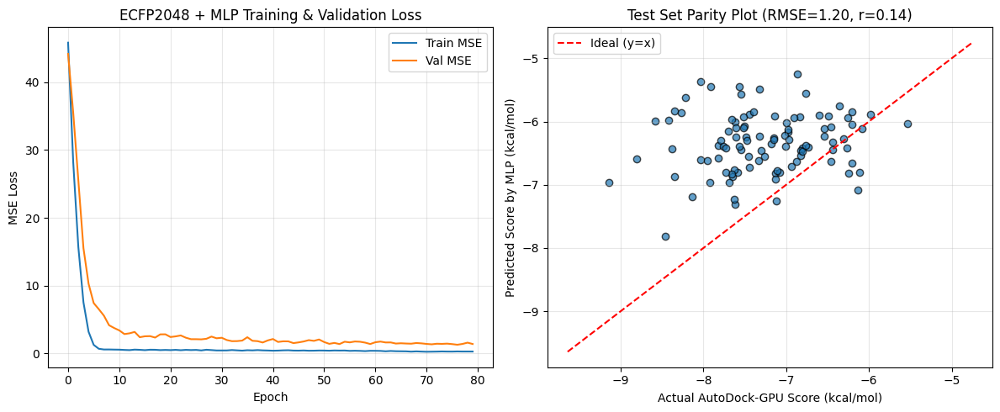

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr, spearmanr

model.eval()
preds_test, targets_test = [], []
with torch.no_grad():
    for bx, by in test_loader:
        bx = bx.to(device)
        pred = model(bx).cpu().numpy().flatten()
        preds_test.extend(pred)
        targets_test.extend(by.numpy().flatten())

preds_test = np.array(preds_test)
targets_test = np.array(targets_test)

rmse = np.sqrt(mean_squared_error(targets_test, preds_test))
mae = mean_absolute_error(targets_test, preds_test)
r2 = r2_score(targets_test, preds_test)
pearson_r, _ = pearsonr(targets_test, preds_test)
spearman_rho, _ = spearmanr(targets_test, preds_test)

print(f"=== Test Set Evaluation ===")
print(f"RMSE        : {rmse:.3f} kcal/mol")
print(f"MAE         : {mae:.3f} kcal/mol")
print(f"R^2         : {r2:.3f}")
print(f"Pearson r   : {pearson_r:.3f}")
print(f"Spearman rho: {spearman_rho:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1) Learning Curve
axes[0].plot(train_losses, label='Train MSE')
axes[0].plot(val_losses, label='Val MSE')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MSE Loss')
axes[0].set_title('ECFP2048 + MLP Training & Validation Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# 2) Parity Plot (Actual vs Predicted Docking Score)
axes[1].scatter(targets_test, preds_test, alpha=0.7, edgecolors='k')
min_v = min(targets_test.min(), preds_test.min()) - 0.5
max_v = max(targets_test.max(), preds_test.max()) + 0.5
axes[1].plot([min_v, max_v], [min_v, max_v], 'r--', label='Ideal (y=x)')
axes[1].set_xlabel('Actual AutoDock-GPU Score (kcal/mol)')
axes[1].set_ylabel('Predicted Score by MLP (kcal/mol)')
axes[1].set_title(f'Test Set Parity Plot (RMSE={rmse:.2f}, r={pearson_r:.2f})')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Part 5 – 나머지 Enamine 라이브러리(459,160개 분자)에서 Top Hit 예측 및 검증
-------
학습된 **ECFP2048 + MLP 도킹 점수 예측기**를 사용하여 아직 도킹하지 않은 **나머지 Enamine Hit Locator Library 전체(`df_remaining`, 459,160개 분자)**의 도킹 점수를 고속 예측합니다.
- 46만 개 분자를 한 번에 메모리에 올리지 않고 **Chunk 단위(예: 10,000개씩)**로 ECFP2048 변환 및 GPU 추론을 수행하여 Colab 메모리 제한 내에서 수 분 내에 전체 라이브러리를 스크리닝합니다.
- 예측된 도킹 점수가 가장 낮은(결합력이 가장 강할 것으로 예측되는) **Top Hit 분자(예: Top 100 / Top 20)**를 선정하고, RDKit 2D 구조 가시화 및 실제 AutoDock-GPU 재도킹으로 검증합니다.

In [ ]:
# 나머지 Enamine 라이브러리 전체(또는 실습 시간 단축을 위해 원하는 개수 설정 가능)에 대해 배치 추론 수행
# 전체 459,160개를 모두 예측하려면 SCREEN_LIMIT = None 으로 두세요.
SCREEN_LIMIT = None  # 예: 빠른 테스트 시 50000, 전체 실행 시 None

df_target_pool = df_remaining.iloc[:SCREEN_LIMIT].copy().reset_index(drop=True) if SCREEN_LIMIT else df_remaining.copy().reset_index(drop=True)
print(f"Surrogate MLP 스크리닝 대상 분자 수: {len(df_target_pool):,}")

CHUNK_SIZE = 10000
predicted_scores = np.full(len(df_target_pool), np.nan, dtype=np.float32)

model.eval()
smiles_series = df_target_pool['SMILES'].tolist()

for start_idx in tqdm(range(0, len(df_target_pool), CHUNK_SIZE), desc="Screening Remaining Library"):
    end_idx = min(start_idx + CHUNK_SIZE, len(df_target_pool))
    chunk_smiles = smiles_series[start_idx:end_idx]

    chunk_fps = []
    chunk_valid_local_idx = []
    for local_i, smi in enumerate(chunk_smiles):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            chunk_fps.append(mfpgen.GetFingerprintAsNumPy(mol))
            chunk_valid_local_idx.append(local_i)

    if chunk_fps:
        bx = torch.tensor(np.array(chunk_fps, dtype=np.float32), device=device)
        with torch.no_grad():
            preds = model(bx).cpu().numpy().flatten()
        for local_i, score in zip(chunk_valid_local_idx, preds):
            predicted_scores[start_idx + local_i] = score

df_target_pool['predicted_docking_score'] = predicted_scores
df_predicted_hits = df_target_pool.dropna(subset=['predicted_docking_score']).sort_values(
    by='predicted_docking_score', ascending=True
).reset_index(drop=True)

print(f"예측 완료된 분자 수: {len(df_predicted_hits):,}")
print("=== Top 20 Predicted Hits from Remaining Enamine Library ===")
display(df_predicted_hits[['Catalog ID', 'SMILES', 'predicted_docking_score', 'MW', 'ClogP', 'HBD', 'HBA', 'TPSA']].head(20))

Surrogate MLP 스크리닝 대상 분자 수: 459,160


Screening Remaining Library:   0%|          | 0/46 [00:00<?, ?it/s]

예측 완료된 분자 수: 459,160
=== Top 20 Predicted Hits from Remaining Enamine Library ===


,Catalog ID,SMILES,predicted_docking_score,MW,ClogP,HBD,HBA,TPSA
0,Z1172196093,O=S(=O)(CC1CCCCO1)NC=2C=CC=C(C2)C3=NN=C4CCCCCN34,-9.048800,390.502,2.467,1,5,86.11
1,Z1891574997,CC(C)C(=O)N1CCC(CC1)C2=NC(=NO2)C3=CC(=CN3)C(N)=O,-8.718507,331.370,-0.754,2,4,118.11
2,Z30414123,O=C(NC=1C=CC=C(C1)C2=NN=C3CCCCCN23)C=4C=CC=C(C...,-8.585362,400.438,2.630,1,6,103.41
3,Z320118304,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)O,-8.524742,275.261,1.523,2,5,99.60
4,Z30414461,O=C(NC=1C=CC=C(C1)C2=NN=C3CCCCCN23)C=4C=CC5=CC...,-8.486163,382.459,4.350,1,3,59.81
5,Z92052590,CC1=NN(CC2=NC(=NO2)C=3C=CC=C(Cl)C3)C(C)=C1[N+]...,-8.466745,333.730,2.702,0,5,99.88
6,Z1052854496,NC(=O)C=1C=CC(=CC1)S(=O)(=O)N2CCC(C2)N3CCCC3,-8.460987,323.412,0.836,1,4,83.71
7,Z338301122,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)NCC(C...,-8.430513,392.452,3.435,2,4,91.40
8,Z1474292198,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C(C)C)C(=O)NC3CC...,-8.413795,387.391,0.770,3,6,137.57
9,Z338582598,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)NCCCC...,-8.403195,374.392,1.608,2,5,117.70


### 5.1 예측된 Top 100 Hit 저장 및 상위 12개 Top Hit 분자의 2D 화학 구조 시각화

Top 100 predicted hits saved to Google Drive!


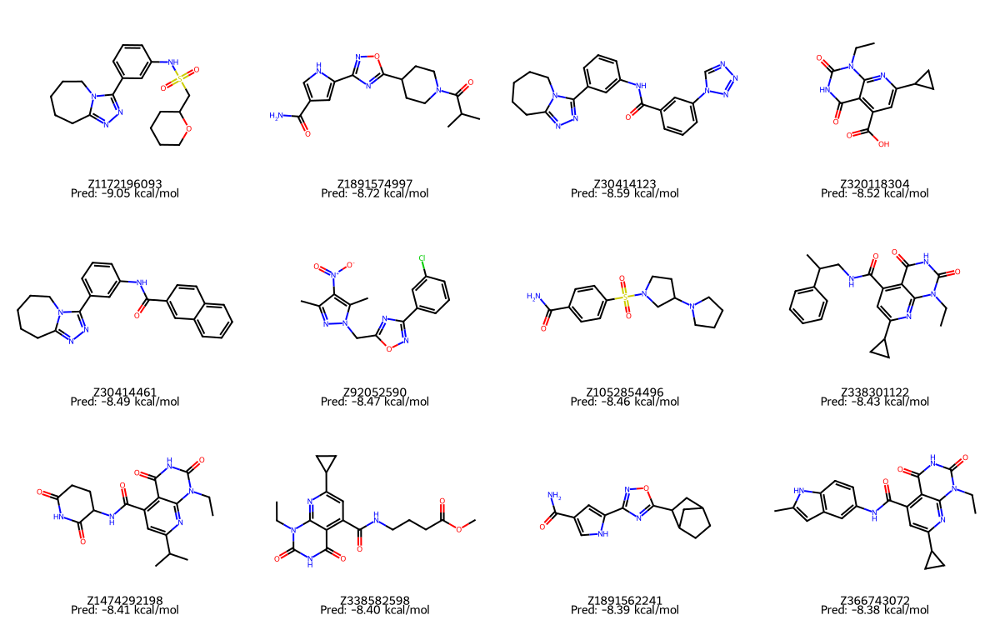

In [ ]:
from rdkit.Chem import Draw

# Top 100 예측 Hit 저장
top100_hits = df_predicted_hits.head(100).copy()
top100_csv_path = '/content/virtual_screening/enamine_MLP_predicted_top100_hits.csv'
top100_hits.to_csv(top100_csv_path, index=False)

if os.path.exists('/content/drive/MyDrive'):
    os.makedirs('/content/drive/MyDrive/virtual_screening', exist_ok=True)
    top100_hits.to_csv('/content/drive/MyDrive/virtual_screening/enamine_MLP_predicted_top100_hits.csv', index=False)
    print("Top 100 predicted hits saved to Google Drive!")

# 상위 12개 분자의 2D 구조 그리드 시각화
top_mols = []
top_legends = []
for _, row in top100_hits.head(12).iterrows():
    mol = Chem.MolFromSmiles(row['SMILES'])
    if mol is not None:
        top_mols.append(mol)
        top_legends.append(f"{row['Catalog ID']}\nPred: {row['predicted_docking_score']:.2f} kcal/mol")

img = Draw.MolsToGridImage(top_mols, molsPerRow=4, subImgSize=(300, 250), legends=top_legends)
display(img)

### 5.2 (검증) MLP가 예측한 Top 20 Hit 분자를 실제로 AutoDock-GPU로 도킹하여 결과 비교
Surrogate 모델이 예측한 상위 20개 Hit 후보물질(`top20_hits`)을 실제로 3D `.pdbqt`로 변환한 뒤 **AutoDock-GPU**로 도킹하여 초기 무작위 1,000개 분자 대비 얼마나 더 우수한 결합 친화도(Enrichment)를 보이는지 검증합니다.

In [ ]:
top20_hits = df_predicted_hits.head(20).copy().reset_index(drop=True)
top20_pdbqt_dir = "/content/enamine_top20_pdbqt"
os.makedirs(top20_pdbqt_dir, exist_ok=True)

top20_batch_file = "/content/virtual_screening/top20_ligand_list.txt"
valid_top20_cids = []

with open(top20_batch_file, 'w') as fout:
    fout.write('/content/virtual_screening/7f7w_prot.maps.fld\n')
    for _, row in top20_hits.iterrows():
        cid, smi = row['Catalog ID'], row['SMILES']
        out_pdbqt = os.path.join(top20_pdbqt_dir, f"{cid}.pdbqt")
        try:
            mol = pybel.readstring("smi", smi)
            mol.addh()
            mol.make3D(forcefield="mmff94", steps=50)
            mol.write("pdbqt", out_pdbqt, overwrite=True)
            if os.path.exists(out_pdbqt) and os.path.getsize(out_pdbqt) > 0:
                fout.write(out_pdbqt + '\n')
                fout.write(f'/content/virtual_screening/top20_{cid}\n')
                valid_top20_cids.append(cid)
        except Exception as e:
            print(f"Conversion failed for {cid}: {e}")

print(f"Prepared {len(valid_top20_cids)} Top Hit ligands for AutoDock-GPU verification.")

Prepared 20 Top Hit ligands for AutoDock-GPU verification.


In [ ]:
%%bash
cd /content/virtual_screening
/content/AutoDock-GPU/bin/autodock_gpu_128wi -B /content/virtual_screening/top20_ligand_list.txt --nrun 20 | tee gpu_top20_out

AutoDock-GPU version: v1.6-20-gbe06a135181178c8631653e1e32d9ece86b5b4d8

Using 2 OpenMP threads

Running 20 docking calculations

Cuda device:                              Tesla T4
Available memory on device:               14425 MB (total: 14912 MB)

CUDA Setup time 0.207154s
(Thread 1 is setting up Job #1)
(Thread 0 is setting up Job #2)

Running Job #1:
    Device: Tesla T4
    Grid map file: /content/virtual_screening/7f7w_prot.maps.fld
    Ligand file: /content/enamine_top20_pdbqt/Z1172196093.pdbqt
    Output file: /content/virtual_screening/top20_Z1172196093.dlg (+ xml)
    Using heuristics: (capped) number of evaluations set to 1132076
    Local-search chosen method is: ADADELTA (ad)

Rest of Setup time 0.036320s

Executing docking runs, stopping automatically after either reaching 0.15 kcal/mol standard deviation of
the best molecules of the last 4 * 5 generations, 42000 generations, or 1132076 evaluations:

Generations |  Evaluations |     Threshold    |  Average energy of best

,Catalog ID,SMILES,predicted_docking_score,actual_autodock_score,MW,ClogP
0,Z1172196093,O=S(=O)(CC1CCCCO1)NC=2C=CC=C(C2)C3=NN=C4CCCCCN34,-9.048800,-9.54,390.502,2.467
1,Z1891574997,CC(C)C(=O)N1CCC(CC1)C2=NC(=NO2)C3=CC(=CN3)C(N)=O,-8.718507,-9.73,331.370,-0.754
2,Z30414123,O=C(NC=1C=CC=C(C1)C2=NN=C3CCCCCN23)C=4C=CC=C(C...,-8.585362,-8.84,400.438,2.630
3,Z320118304,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)O,-8.524742,-8.46,275.261,1.523
4,Z30414461,O=C(NC=1C=CC=C(C1)C2=NN=C3CCCCCN23)C=4C=CC5=CC...,-8.486163,-8.23,382.459,4.350
5,Z92052590,CC1=NN(CC2=NC(=NO2)C=3C=CC=C(Cl)C3)C(C)=C1[N+]...,-8.466745,-8.92,333.730,2.702
6,Z1052854496,NC(=O)C=1C=CC(=CC1)S(=O)(=O)N2CCC(C2)N3CCCC3,-8.460987,-8.51,323.412,0.836
7,Z338301122,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)NCC(C...,-8.430513,-8.03,392.452,3.435
8,Z1474292198,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C(C)C)C(=O)NC3CC...,-8.413795,-9.79,387.391,0.770
9,Z338582598,CCN1C(=O)NC(=O)C=2C(=CC(=NC21)C3CC3)C(=O)NCCCC...,-8.403195,-9.08,374.392,1.608


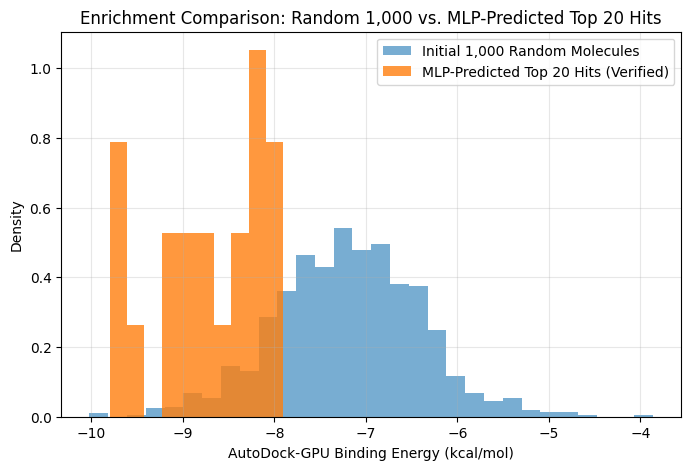

In [ ]:
# Top 20 예측 Hit의 실제 AutoDock-GPU 도킹 점수 확인 및 초기 1,000개 랜덤 샘플과 분포 비교
actual_top20_scores = {}
for cid in valid_top20_cids:
    dlg_path = f"/content/virtual_screening/top20_{cid}.dlg"
    if os.path.exists(dlg_path):
        actual_top20_scores[cid] = get_min_affinity(dlg_path)

top20_hits['actual_autodock_score'] = top20_hits['Catalog ID'].map(actual_top20_scores)
display(top20_hits[['Catalog ID', 'SMILES', 'predicted_docking_score', 'actual_autodock_score', 'MW', 'ClogP']])

plt.figure(figsize=(8, 5))
plt.hist(df_docked_results['docking_score'], bins=30, alpha=0.6, density=True, label='Initial 1,000 Random Molecules')
plt.hist(top20_hits['actual_autodock_score'].dropna(), bins=10, alpha=0.8, density=True, label='MLP-Predicted Top 20 Hits (Verified)')
plt.xlabel('AutoDock-GPU Binding Energy (kcal/mol)')
plt.ylabel('Density')
plt.title('Enrichment Comparison: Random 1,000 vs. MLP-Predicted Top 20 Hits')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

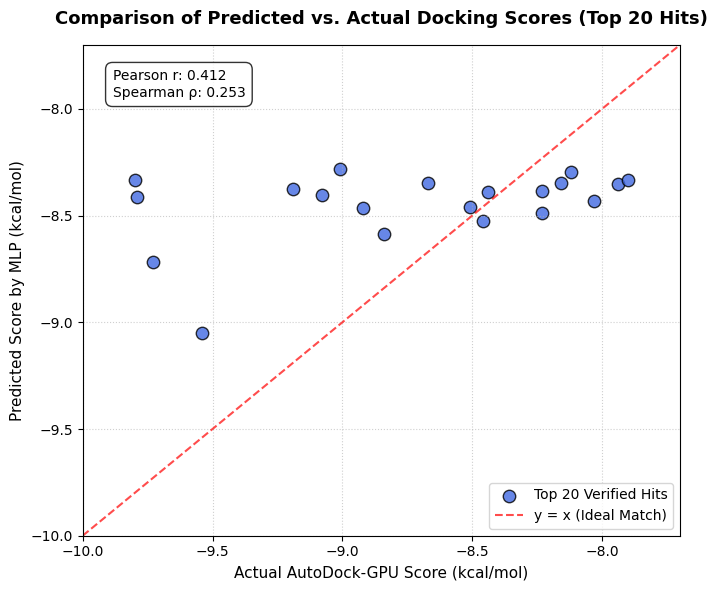

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr, spearmanr

# Filter out any rows that might have NaN in actual scores
plot_data = top20_hits.dropna(subset=['actual_autodock_score']).copy()

actuals = plot_data['actual_autodock_score'].values
predicts = plot_data['predicted_docking_score'].values

# Calculate correlation metrics
pe_r, _ = pearsonr(actuals, predicts)
sp_rho, _ = spearmanr(actuals, predicts)

plt.figure(figsize=(7, 6))
plt.scatter(actuals, predicts, color='royalblue', alpha=0.8, edgecolors='black', s=80, label='Top 20 Verified Hits')

# Ideal y=x diagonal line or regression line guide
all_vals = np.concatenate([actuals, predicts])
min_v, max_v = all_vals.min() - 0.2, all_vals.max() + 0.2
plt.plot([min_v, max_v], [min_v, max_v], 'r--', alpha=0.7, label='y = x (Ideal Match)')

plt.title('Comparison of Predicted vs. Actual Docking Scores (Top 20 Hits)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Actual AutoDock-GPU Score (kcal/mol)', fontsize=11)
plt.ylabel('Predicted Score by MLP (kcal/mol)', fontsize=11)

# Add correlation coefficients in a text box
stats_text = f'Pearson r: {pe_r:.3f}\nSpearman \u03c1: {sp_rho:.3f}'
plt.gca().text(0.05, 0.95, stats_text, transform=plt.gca().transAxes,
            fontsize=10, verticalalignment='top', bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.8))

plt.xlim(min_v, max_v)
plt.ylim(min_v, max_v)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 5.3 최상위 예측 Hit 분자의 도킹 포즈 PDB 변환 및 3D 결합 구조 시각화

In [ ]:
from openbabel import openbabel

best_hit_row = top20_hits.dropna(subset=['actual_autodock_score']).sort_values('actual_autodock_score').iloc[0]
best_cid = best_hit_row['Catalog ID']
best_dlg = f"/content/virtual_screening/top20_{best_cid}.dlg"
best_docked_pdb = f"/content/virtual_screening/top20_{best_cid}.docked.pdb"

obConversion = openbabel.OBConversion()
obConversion.SetInAndOutFormats("pdbqt", "pdb")
obConversion.AddOption("d", openbabel.OBConversion.INOPTIONS)
obConversion.AddOption("a", openbabel.OBConversion.INOPTIONS)
obConversion.AddOption("errorlevel", openbabel.OBConversion.GENOPTIONS, "5")

mol = openbabel.OBMol()
if obConversion.ReadFile(mol, best_dlg):
    obConversion.WriteFile(mol, best_docked_pdb)
    print(f"Best Hit ({best_cid}) Actual Score: {best_hit_row['actual_autodock_score']:.2f} kcal/mol -> Saved to {best_docked_pdb}")

visualize_molecules("/content/virtual_screening/7f7w_prot.pdb", best_docked_pdb)

Best Hit (Z1228056512) Actual Score: -9.80 kcal/mol -> Saved to /content/virtual_screening/top20_Z1228056512.docked.pdb
An error occurred during visualization: 'view' object is not callable


In [ ]:
from openbabel import openbabel
import os

# 정렬된 top20_hits 분자들을 가져옵니다. (실제 AutoDock 점수 기준 혹은 예측 점수 기준)
# 실제 도킹 점수가 있는 분자들을 오름차순(가장 결합력이 좋은 순)으로 정렬합니다.
top20_sorted = top20_hits.dropna(subset=['actual_autodock_score']).sort_values('actual_autodock_score').reset_index(drop=True)

output_dir = "/content/virtual_screening/"
os.makedirs(output_dir, exist_ok=True)

obConversion = openbabel.OBConversion()
obConversion.SetInAndOutFormats("pdbqt", "pdb")
obConversion.AddOption("d", openbabel.OBConversion.INOPTIONS)  # Input ligand coordinates
obConversion.AddOption("a", openbabel.OBConversion.INOPTIONS)  # Keep all coordinates / conformations
obConversion.AddOption("errorlevel", openbabel.OBConversion.GENOPTIONS, "5")

saved_files = []

for i, row in top20_sorted.iterrows():
    cid = row['Catalog ID']
    score = row['actual_autodock_score']
    dlg_path = f"/content/virtual_screening/top20_{cid}.dlg"
    out_pdb_name = f"round1_top{i+1}.pdb"
    out_pdb_path = os.path.join(output_dir, out_pdb_name)

    if os.path.exists(dlg_path):
        mol = openbabel.OBMol()
        if obConversion.ReadFile(mol, dlg_path):
            obConversion.WriteFile(mol, out_pdb_path)
            saved_files.append((out_pdb_name, cid, score))
            print(f"Saved {out_pdb_name} | Catalog ID: {cid} | Score: {score:.2f} kcal/mol")
    else:
        print(f"Warning: DLG file not found for {cid} ({dlg_path})")

print(f"\n총 {len(saved_files)}개의 PDB 파일이 저장되었습니다.")

Saved round1_top1.pdb | Catalog ID: Z1228056512 | Score: -9.80 kcal/mol
Saved round1_top2.pdb | Catalog ID: Z1474292198 | Score: -9.79 kcal/mol
Saved round1_top3.pdb | Catalog ID: Z1891574997 | Score: -9.73 kcal/mol
Saved round1_top4.pdb | Catalog ID: Z1172196093 | Score: -9.54 kcal/mol
Saved round1_top5.pdb | Catalog ID: Z729867746 | Score: -9.19 kcal/mol
Saved round1_top6.pdb | Catalog ID: Z338582598 | Score: -9.08 kcal/mol
Saved round1_top7.pdb | Catalog ID: Z1682201859 | Score: -9.01 kcal/mol
Saved round1_top8.pdb | Catalog ID: Z92052590 | Score: -8.92 kcal/mol
Saved round1_top9.pdb | Catalog ID: Z30414123 | Score: -8.84 kcal/mol
Saved round1_top10.pdb | Catalog ID: Z69202160 | Score: -8.67 kcal/mol
Saved round1_top11.pdb | Catalog ID: Z1052854496 | Score: -8.51 kcal/mol
Saved round1_top12.pdb | Catalog ID: Z320118304 | Score: -8.46 kcal/mol
Saved round1_top13.pdb | Catalog ID: Z1891562241 | Score: -8.44 kcal/mol
Saved round1_top14.pdb | Catalog ID: Z30414461 | Score: -8.23 kcal/mo

In [ ]:
#@title Visualizing predicted binding site with native ligand
%%capture

import os
import py3Dmol
from py3Dmol import view
from openbabel import pybel

def read_pdb_as_string(file_path):
    """Read the PDB file content as a string."""
    with open(file_path, 'r') as file:
        return file.read()

def visualize_molecules(protein_path, ligand_path=None, pocket_paths=None, label_residues=False):
    """
    Visualizes the protein, ligand, and predicted pockets using Py3Dmol.
    Adds residue labels with residue names and numbers for the pockets if `label_residues` is True.
    """
    try:
        viewer = view(width=1200, height=800)

        # Add protein
        protein_data = read_pdb_as_string(protein_path)
        if protein_data:
            viewer.addModel(protein_data, 'pdb')
            viewer.setStyle({'model': 0}, {'cartoon': {'color': 'white'}})

        # Add ligand
        if ligand_path and os.path.exists(ligand_path):
            ligand_data = read_pdb_as_string(ligand_path)
            viewer.addModel(ligand_data, 'pdb')
            viewer.setStyle({'model': 1}, {'stick': {'radius': 0.3, 'color': 'red'}})

        # Add pockets and optionally label residues
        if pocket_paths:
            pocket_path = pocket_paths[0]
            if os.path.exists(pocket_path):
                pocket_data = read_pdb_as_string(pocket_path)
                viewer.addModel(pocket_data, 'pdb')
                viewer.setStyle({'model': 2 + i}, {'sphere': {'opacity': 0.4, 'color': 'blue'}})

                if label_residues:
                    # Extract residues and label them
                    lines = pocket_data.splitlines()
                    for line in lines:
                        if line.startswith("ATOM") or line.startswith("HETATM"):
                            residue_name = line[17:20].strip()
                            residue_number = line[22:26].strip()
                            chain_id = line[21].strip()
                            viewer.addLabel(
                                f"{residue_name} {residue_number}",
                                {
                                    'position': {
                                        'x': float(line[30:38].strip()),
                                        'y': float(line[38:46].strip()),
                                        'z': float(line[46:54].strip())
                                    },
                                    'backgroundColor': 'white',
                                    'fontColor': 'black',
                                    'fontSize': 10
                                },
                                {'chain': chain_id, 'resi': int(residue_number)}
                            )

        # Adjust view
        viewer.zoomTo()
        viewer.show()
    except Exception as e:
        print(f"An error occurred during visualization: {e}")

In [ ]:
visualize_molecules("/content/virtual_screening/7f7w_prot.pdb", best_docked_pdb)

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [ ]:
visualize_molecules("/content/virtual_screening/7f7w_prot.pdb", "/content/virtual_screening/round1_top2.pdb")

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

# Running GNINA
--------

Running GNINA for AI-based scoring

https://github.com/gnina/gnina

https://jcheminf.biomedcentral.com/articles/10.1186/s13321-021-00522-2

In [ ]:
!wget https://github.com/gnina/gnina/releases/download/v1.1/gnina

--2026-10-27 22:09:13--  https://github.com/gnina/gnina/releases/download/v1.1/gnina
Resolving github.com (github.com)... 20.205.243.166
Connecting to github.com (github.com)|20.205.243.166|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/45548146/bc227ff8-7934-457d-95b3-eab58982638a?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-27T22%3A42%3A29Z&rscd=attachment%3B+filename%3Dgnina&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-27T21%3A42%3A17Z&ske=2026-10-27T22%3A42%3A29Z&sks=b&skv=2018-11-09&sig=FASM5mS9iH1v%2BYvXAHsCHaoZUSYKN07Gu3LGmehLnrQ%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MzE0MjU1MywibmJmIjoxNzkzMTM4OTUzLCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5ibG9iLmNvcmUud2luZG93cy5uZXQ

In [ ]:
!chmod +x gnina

In [ ]:
%alias gnina /content/gnina

In [ ]:
!./gnina --help


Input:
  -r [ --receptor ] arg              rigid part of the receptor
  --flex arg                         flexible side chains, if any (PDBQT)
  -l [ --ligand ] arg                ligand(s)
  --flexres arg                      flexible side chains specified by comma 
                                     separated list of chain:resid
  --flexdist_ligand arg              Ligand to use for flexdist
  --flexdist arg                     set all side chains within specified 
                                     distance to flexdist_ligand to flexible
  --flex_limit arg                   Hard limit for the number of flexible 
                                     residues
  --flex_max arg                     Retain at at most the closest flex_max 
                                     flexible residues

Search space (required):
  --center_x arg                     X coordinate of the center
  --center_y arg                     Y coordinate of the center
  --center_z arg                     Z

### GNINA를 사용하여 단백질-리간드의 결합 구조를 예측
--------


GNINA는 Autodock 코드에 기반하여 개발된 프로그램이라서 내부적으로 Autodock을 실행해서 직접적으로 docking pose를 생성할 수 있음.


 이전에 계산했던 Ligand의 중심 좌표를 docking을 위한 중심 좌표로 활용함: (24.397, -12.206, 1.935)

In [ ]:
!./gnina  -r /content/virtual_screening/7f7w_prot.pdbqt \
          -l /content/ligands/Abiraterone.smiles.pdbqt \
          --center_x 24.4 \
          --center_y -12.2 \
          --center_z 1.9  \
          --size_x 20 \
          --size_y 20 \
          --size_z 20 \
          --cnn crossdock_default2018 \
          --cnn_scoring rescore \
          -o drug_1_docked.sdf \
          --seed 12345



Error: could not open "/content/ligands/Abiraterone.smiles.pdbqt" for reading.


### Autodock-GPU를 활용해서 얻은 Protein-ligand 복합체 구조를 Gnina를 활용해서 다시 결합친화도를 계산
------


In [ ]:
for f in glob.glob('/content/virtual_screening/*.docked[1-9]*.sdf'): # 전체 결합 구조에 대해서 반복
 !/content/gnina -r /content/virtual_screening/7f7w_prot.pdbqt -l $f --score_only

Virtual screening using GNINA
----------


* 아래 코드를 실행하면 ```/content/ligands/``` 디렉토리에 있는 pdbqt 파일들을 읽어들여 7f7w_prot.pdbqt 단백질 파일을 활용하여 docking을 수행함.



* 아래 코드의 결과 ```/content/gnina_results/```  디렉토리에 단백질-리간드 결합구조 파일과 로그 파일이 생성됨.



* 결합 구조 파일은 sdf 포맷으로 저장되며, 출력 로그 파일은 gnina_out 확장자를 가진 파일로 저장됨.

In [ ]:
import glob
files = sorted(glob.glob("/content/ligands/A[a-l]*.pdbqt"))

gnina_output_path = '/content/gnina_results'
if not os.path.exists(gnina_output_path):
  os.mkdir(gnina_output_path)

# 실습을 위해서는 10개의 리간드에 대해서 docking을 수행함.
# 실제 계산에서는 전체 리간드 파일을 사용해야 함.
for ligand_pdbqt in files[:10]:
  print(ligand_pdbqt)
  fname = ligand_pdbqt.split(os.path.sep)[-1].split('.')[0]
  output_path = gnina_output_path + '/' + fname # output file name
  !/content/gnina  -r /content/virtual_screening/7f7w_prot.pdbqt \
            -l {ligand_pdbqt} \
            --center_x 24.4  \
            --center_y -12.2 \
            --center_z 1.9   \
            --size_x 20.0    \
            --size_y 20.0    \
            --size_z 20.0    \
            --exhaustiveness 2 \
            --cnn crossdock_default2018 \
            -o {output_path}_docked.sdf | tee {output_path}.gnina_out

아래 함수는 gnina_out 로그 파일을 읽어들여서 **CNN pose score가 0.5 이상**인 구조들 중에서 **가장 높은 CNN affinity score (pKd 값)**을 추출한다.




In [ ]:
def obtain_best_affinity(filename):
  """
  This code extracts the best CNN affinity value among the multiple conformations.
  """
  with open(filename, 'r') as f:
    lines = f.readlines()

  affinity_list = [0.0]
  for idx, l in enumerate(lines):
    if l.startswith('-----+'):
      break
  for l in lines[idx+1:]:
      mode, affinity, intramol, cnn_pose_score, cnn_affinity = map(float, l.strip().split())
      if cnn_pose_score > 0.5:
        affinity_list.append(cnn_affinity)

  return max(affinity_list)

In [ ]:
output_log_files = glob.glob(gnina_output_path + '/*.gnina_out')
ligand_best_affinity = []

for f in output_log_files:
  print(f)
  max_affinity = obtain_best_affinity(f)
  ligand_name = f.split(os.path.sep)[-1].split('.')[0]
  ligand_best_affinity.append((ligand_name, max_affinity))

ligand_best_affinity.sort(key=lambda x: x[1], reverse=True)

print("Top5 affinity ligands:")
print(ligand_best_affinity[:5])
#

Top5 affinity ligands:
[]


Converting SDF file to PDB file.

In [ ]:
!obabel -m -isdf  /content/gnina_results/Abiraterone_docked.sdf  -opdb  -O /content/gnina_results/Abiraterone_docked.pdb -m

*** Open Babel Error  in OpenAndSetFormat
  Cannot open /content/gnina_results/Abiraterone_docked.sdf
0 molecules converted
free(): double free detected in tcache 2


In [ ]:
!obabel --version

No input file or format spec or possibly a misplaced option.
Most options must come after the input files. (-i -o -O -m can be anywhwere.)

Open Babel 2.4.1 -- Jan 25 2017 -- 17:44:52
Usage:
obabel [-i<input-type>] <infilename> [-o<output-type>] -O<outfilename> [Options]
Try  -H option for more information.


In [ ]:
print('Splitting all conformations from Abiraterone.docked.pdbqt into individual PDB files:')
!obabel -m -ipdbqt /content/virtual_screening/Abiraterone.docked.pdbqt -opdb -O /content/virtual_screening/Abiraterone.docked.pdb

Splitting all conformations from Abiraterone.docked.pdbqt into individual PDB files:
*** Open Babel Error  in OpenAndSetFormat
  Cannot open /content/virtual_screening/Abiraterone.docked.pdbqt
0 molecules converted
free(): double free detected in tcache 2


In [ ]:
visualize_molecules("/content/virtual_screening/7f7w_prot.pdbqt", ligand_path="/content/gnina_results/Abiraterone_docked.sdf")

An error occurred during visualization: 'view' object is not callable


## Homework
---------
Gnina를 활용해서 분자이름이 A로 시작하는 분자들을 모두 docking하고 CNN affinity 값이 가장 큰 순서대로 정렬하시오.

Hint: Docking 결과는 /content/gnina_results/*.gnina_out 파일들에 저장되어 있으므로 이를 parsing 하면 가능.


